# Module 1 Bridge -- combined FIRE + LongDR + Tianjin caching

Replaces notebooks 04 and 05's caching cells with a single session: one Drive mount, one
GitHub token, one repo clone, no manual file upload needed on this branch. Builds
all 3 Module 1 output caches (FIRE, LongDR, Tianjin) that notebook 06 needs for the real
combined Module 2 training run.

**Deliberately does NOT run notebook 04's own standalone Module 2 training cell** -- that was
a throwaway 5-epoch FIRE+LongDR-only POC that nothing downstream actually reads (notebook 06
trains its own Module 2 checkpoint from scratch using all 3 sources, and notebook 08 reads
06's checkpoint, not 04's). Skipping it saves a full training run for zero loss.

**After this notebook finishes:** go straight to notebook 06, then 07 and 08.

**Round 4** (first code cell: `ROUND_TAG`, `DRP_RETINA_CROP`, `DRP_LONGDR_FOLDER`): caches go to new
`..._r4` folders, LongDR is cached from its raw colour photos (`FundusImagesColor`) instead of the
contrast-normalised ones, and notebook 11's fine-tuned segmenters are used once they exist. Two
Phase-0 checks run here: LongDR normalised vs colour lesion maps (before the LongDR cache), and the
grader-resolution check plus an LBS-by-grade summary per source (at the end).

**`MODULE1_SOURCE`** (first code cell) picks the Module 1 models: `'drgnet_combined'` (default) = notebook 11's FGADR classifier + FGADR + DDR combined lesion segmenters (caches go to `module1_cache_drgnet_comb/`); `'drgnet'` = notebook 11's FGADR classifier + FGADR-only segmenters (`module1_cache_drgnet/`); `'poc'` = notebooks 02/03's (`module1_cache/`). Each setting has its own folders, so nothing is overwritten when you switch.


In [2]:
from google.colab import drive
drive.mount('/content/drive')
# Free Drive space: the training notebooks save checkpoints and caches here (several GB in total).
# Deleted or overwritten files stay in the Drive Trash and still count -- empty it if space is low.
import shutil as _shutil
try:
    _du = _shutil.disk_usage('/content/drive/MyDrive')
    print(f'Google Drive: {_du.free / 1e9:.1f} GB free of {_du.total / 1e9:.1f} GB')
    if _du.free < 10e9:
        print('⚠ Under 10 GB free on Google Drive -- model files may fail to save. Empty the Trash '
              '(drive.google.com/drive/trash) or free space before training.')
except OSError:
    pass

import getpass, os

GITHUB_TOKEN = getpass.getpass('GitHub Personal Access Token (repo scope): ')

REPO_OWNER = 'Mieka068'
REPO_NAME = 'DRProgression'
REPO_BRANCH = 'R5-Round3Baseline-Fixes'  # <-- round 5; 'AllModuleEdits-PreFinals' = rounds 3/4, 'mod-2-NonLongIntegration' = the earlier runs
REPO_CODE_SUBDIR = 'M2-DRProgression-VerM-module1-fgadr-poc'

DRIVE_DATA_DIR = '/content/drive/MyDrive/Thesis_Datasets'  # <-- change if you used a different folder
assert os.path.isdir(DRIVE_DATA_DIR), f"Not found: {DRIVE_DATA_DIR}"

# Which Module 1 models the pipeline uses -- set the SAME value in notebooks 04_05 and 06-10:
#   'drgnet' -- notebook 11's DRG-Net replication checkpoints (module1_runs/drgnet_replication/)
#   'poc'    -- notebooks 02/03's original POC checkpoints (module1_runs/)
# Everything built from Module 1's outputs (Module 1 caches, Module 2 runs, figures) gets a
# '_drgnet' suffix for 'drgnet', so the two pipelines never overwrite each other's results.
MODULE1_SOURCE = 'drgnet_combined'
assert MODULE1_SOURCE in ('drgnet_combined', 'drgnet', 'poc'), MODULE1_SOURCE
# New Drive folders for this branch's runs: every Module 1 cache / Module 2 / Module 3 folder below
# gets RUN_SUFFIX, so the mod-2-NonLongIntegration results stay untouched for before/after
# comparison. '' = read/write the earlier folders again.
RUN_SUFFIX = '_prefinals'
RUN_TAG = {'drgnet_combined': '_drgnet_comb', 'drgnet': '_drgnet', 'poc': ''}[MODULE1_SOURCE] + RUN_SUFFIX
# Round 4: every Module 1 cache / Module 2 / Module 3 folder ALSO gets ROUND_TAG, so round 3's results
# (no ROUND_TAG) stay untouched for before/after comparison -- the SAME value in notebooks 04_05 and 06-10.
# Model folders (notebook 11) and the laterality file keep RUN_SUFFIX only. '' = round 3's folders.
ROUND_TAG = '_r5'
# Round 5 (branch R5-Round3Baseline-Fixes): round 3's Module 2 settings (128 px, no grader loss, round 3's
# best-epoch rule) + the data fixes (text-safe retina crop, SIFT failures dropped). '_r4' = round 4's folders.
RUN_TAG += ROUND_TAG
# Image preprocessing for every script this notebook runs (fundus_preprocess.py), the same in 04_05-10:
#   DRP_RETINA_CROP '1' = crop to the retina and pad to square before resizing (Tianjin's 3:2 and LongDR's
#     2000x1312 photos were squashed into ovals); '0' = round 3's plain resize.
#   DRP_LONGDR_FOLDER 'FundusImagesColor' = LongDR's raw colour photos. Round 3 used FundusImagesNormalized,
#     on which the lesion segmenters (trained on raw photos) marked 10-30 % of a NORMAL retina as lesion
#     (LBS 0.1-0.34 at grade 0, vs ~0.001 on Tianjin/FIRE) -- 559 of the 917 Module 2 pairs.
os.environ['DRP_RETINA_CROP'] = '1'
os.environ['DRP_LONGDR_FOLDER'] = 'FundusImagesColor'
MODULE1_RUNS = os.path.join(DRIVE_DATA_DIR, 'module1_runs', *(['drgnet_replication'] if MODULE1_SOURCE != 'poc' else []))
# Notebook 11 on this branch writes its models to drgnet_replication<RUN_SUFFIX>/ (tiled evaluation,
# 200 segmentation epochs, optional EyePACS grader); use those once they exist.
if MODULE1_SOURCE != 'poc' and os.path.isdir(os.path.join(MODULE1_RUNS + RUN_SUFFIX, 'segmentation')):
    MODULE1_RUNS += RUN_SUFFIX
elif MODULE1_SOURCE != 'poc' and RUN_SUFFIX:
    print(f'\u26a0 {MODULE1_RUNS + RUN_SUFFIX} not found -- using the earlier Module 1 models in {MODULE1_RUNS}. '
          'Run notebook 11 on this branch first for the re-trained ones.')
# Lesion segmenters: <MODULE1_RUNS>/segmentation/<SEG_MODEL_PREFIX><lesion>/model_2.pth.tar --
# FGADR + DDR combined (notebook 11) or FGADR only. The classifier is FGADR's either way.
SEG_MODEL_PREFIX = 'comb_models_' if MODULE1_SOURCE == 'drgnet_combined' else 'models_FGADR_NO_TATL_'
# Round 4: notebook 11's fine-tuned combined segmenters (comb_ft_models_*) once all four exist.
if MODULE1_SOURCE == 'drgnet_combined':
    if all(os.path.isfile(os.path.join(MODULE1_RUNS, 'segmentation', f'comb_ft_models_{_l}', 'model_2.pth.tar'))
           for _l in ('ex', 'he', 'ma', 'se')):
        SEG_MODEL_PREFIX = 'comb_ft_models_'
    elif ROUND_TAG:
        print('\u26a0 Fine-tuned segmenters (comb_ft_models_*) not all on Drive yet -- using the 200-epoch '
              'comb_models_*. Run notebook 11 (RUN["comb_seg_ft"]) first for round 4.')
print('Lesion segmenters:', SEG_MODEL_PREFIX + '<lesion>')
MODULE1_CACHE_DIR = os.path.join(DRIVE_DATA_DIR, 'module1_cache' + RUN_TAG)
os.makedirs(MODULE1_CACHE_DIR, exist_ok=True)
print('Module 1 source:', MODULE1_SOURCE, '| models:', MODULE1_RUNS, '| caches:', MODULE1_CACHE_DIR)
TIANJIN_ZIP = os.path.join(DRIVE_DATA_DIR, 'retinal-dr-longitudinal.zip')
assert os.path.isfile(TIANJIN_ZIP), f"Not found: {TIANJIN_ZIP}"


Mounted at /content/drive
Google Drive: 166.6 GB free of 214.7 GB
GitHub Personal Access Token (repo scope): ··········
Lesion segmenters: comb_ft_models_<lesion>
Module 1 source: drgnet_combined | models: /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals | caches: /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r5
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive: 166.6 GB free of 214.7 GB
GitHub Personal Access Token (repo scope): ··········
Lesion segmenters: comb_ft_models_<lesion>
Module 1 source: drgnet_combined | models: /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals | caches: /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r5


In [3]:
# Unzip FIRE + LongDR + Tianjin. -n skips files that already exist, so safe/cheap to re-run.
import glob, shutil

os.makedirs('/content/data', exist_ok=True)
%cd /content/data
!unzip -q -n "$DRIVE_DATA_DIR/FIRE_dataset.zip"
!unzip -q -n "$DRIVE_DATA_DIR/LongDRScreening_20150209.zip" -d LongDRScreening_20150209
!unzip -q -n "$TIANJIN_ZIP" -d _tianjin_extract_raw

_manifest_candidates = glob.glob('/content/data/_tianjin_extract_raw/**/corrected_manifest.csv', recursive=True)
assert _manifest_candidates, 'No corrected_manifest.csv found under the extracted Tianjin zip.'
_tianjin_root = os.path.dirname(_manifest_candidates[0])
TIANJIN_DIR = '/content/data/retinal-dr-longitudinal'
if _tianjin_root != TIANJIN_DIR and not os.path.exists(TIANJIN_DIR):
    os.symlink(_tianjin_root, TIANJIN_DIR)

print('FIRE Images present :', os.path.isdir('/content/data/FIRE_dataset/FIRE/Images'))
print('LongDR norm present :', os.path.isdir('/content/data/LongDRScreening_20150209/FundusImagesNormalized'))
print('LongDR colour present:', os.path.isdir('/content/data/LongDRScreening_20150209/FundusImagesColor'))
LONGDR_IMAGES = os.path.join('/content/data/LongDRScreening_20150209', os.environ['DRP_LONGDR_FOLDER'])
assert os.path.isdir(LONGDR_IMAGES), f'{LONGDR_IMAGES} not in the LongDR zip -- set DRP_LONGDR_FOLDER in the first cell'
print('Tianjin dir present :', os.path.isdir(TIANJIN_DIR))


/content/data
FIRE Images present : True
LongDR norm present : True
LongDR colour present: True
Tianjin dir present : True


In [4]:
# Clone the repo once and install everything both the FIRE/LongDR and Tianjin steps need.
%cd /content
if not os.path.isdir(f'/content/{REPO_NAME}'):
    !git clone --branch {REPO_BRANCH} https://{GITHUB_TOKEN}@github.com/{REPO_OWNER}/{REPO_NAME}.git {REPO_NAME}

REPO_CODE_DIR = f'/content/{REPO_NAME}/{REPO_CODE_SUBDIR}'
assert os.path.isdir(REPO_CODE_DIR), f"Not found: {REPO_CODE_DIR}"

%cd {REPO_CODE_DIR}
!pip install -q pandas openpyxl segmentation-models-pytorch opencv-python-headless


/content
Cloning into 'DRProgression'...
remote: Enumerating objects: 1091, done.
remote: Counting objects: 100% (257/257), done.
remote: Compressing objects: 100% (114/114), done.
remote: Total 1091 (delta 173), reused 197 (delta 143), pack-reused 834 (from 1)
Receiving objects: 100% (1091/1091), 39.03 MiB | 13.07 MiB/s, done.
Resolving deltas: 100% (658/658), done.
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc


In [5]:
# Item 7.3: image-size distribution of the three longitudinal datasets (LongDR's and Tianjin's sizes
# were undocumented) -- for the methods section. Header-only reads, a few seconds. Saved to Drive.
%cd {REPO_CODE_DIR}
!python tools/dataset_image_sizes.py fire=/content/data/FIRE_dataset longdr=/content/data/LongDRScreening_20150209 tianjin="{TIANJIN_DIR}" --out "{MODULE1_CACHE_DIR}/dataset_image_sizes.json"

/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc

fire (/content/data/FIRE_dataset): 268 images
  most common: 2912x2912 (268)
  width  min/median/max: 2912 / 2912 / 2912
  height min/median/max: 2912 / 2912 / 2912
  non-square: 0.0%

longdr (/content/data/LongDRScreening_20150209): 2520 images
  most common: 2000x1312 (2240), 2324x1810 (2), 2268x1771 (1), 2254x1786 (1), 2415x1793 (1)
  width  min/median/max: 1622 / 2000 / 2859
  height min/median/max: 1200 / 1312 / 2650
  non-square: 100.0%

tianjin (/content/data/retinal-dr-longitudinal): 2412 images
  most common: 2992x2000 (1233), 3472x2320 (1146), 2576x1934 (32), 2144x1424 (1)
  width  min/median/max: 2144 / 2992 / 3472
  height min/median/max: 1424 / 2000 / 2320
  non-square: 100.0%

Wrote /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r5/dataset_image_sizes.json


### Round 5: retina-crop check on real Tianjin photos

Before the caches are built: round 5's crop should ignore the text Tianjin prints in the black border (ID, date, "R / Color") and fill the frame with the retina. Round 4's box stretched over that text (retina ~60 % of the frame). Expect round 5 at ~100 % on every photo; if the cell warns, stop and look at the flagged photos.

200 Tianjin photos measured; retina fill of the cropped frame (median):
                   fill_r4 fill_r5   n
kind      has_text                    
baseline  False       100%    100%  99
          True         67%    100%   1
follow-up False       100%    100%  37
          True         62%    100%  63

⚠ 1 photo(s) where round 5's crop may be wrong (no retina found, retina under 85% of the frame, or a big bright region besides the retina) -- look at them before building the caches:
                                       photo     kind  fill_r4  fill_r5  retina_share  no_box
baseline fundus images/02668/02668-30372.jpg baseline 0.667969 0.999781      0.504536   False


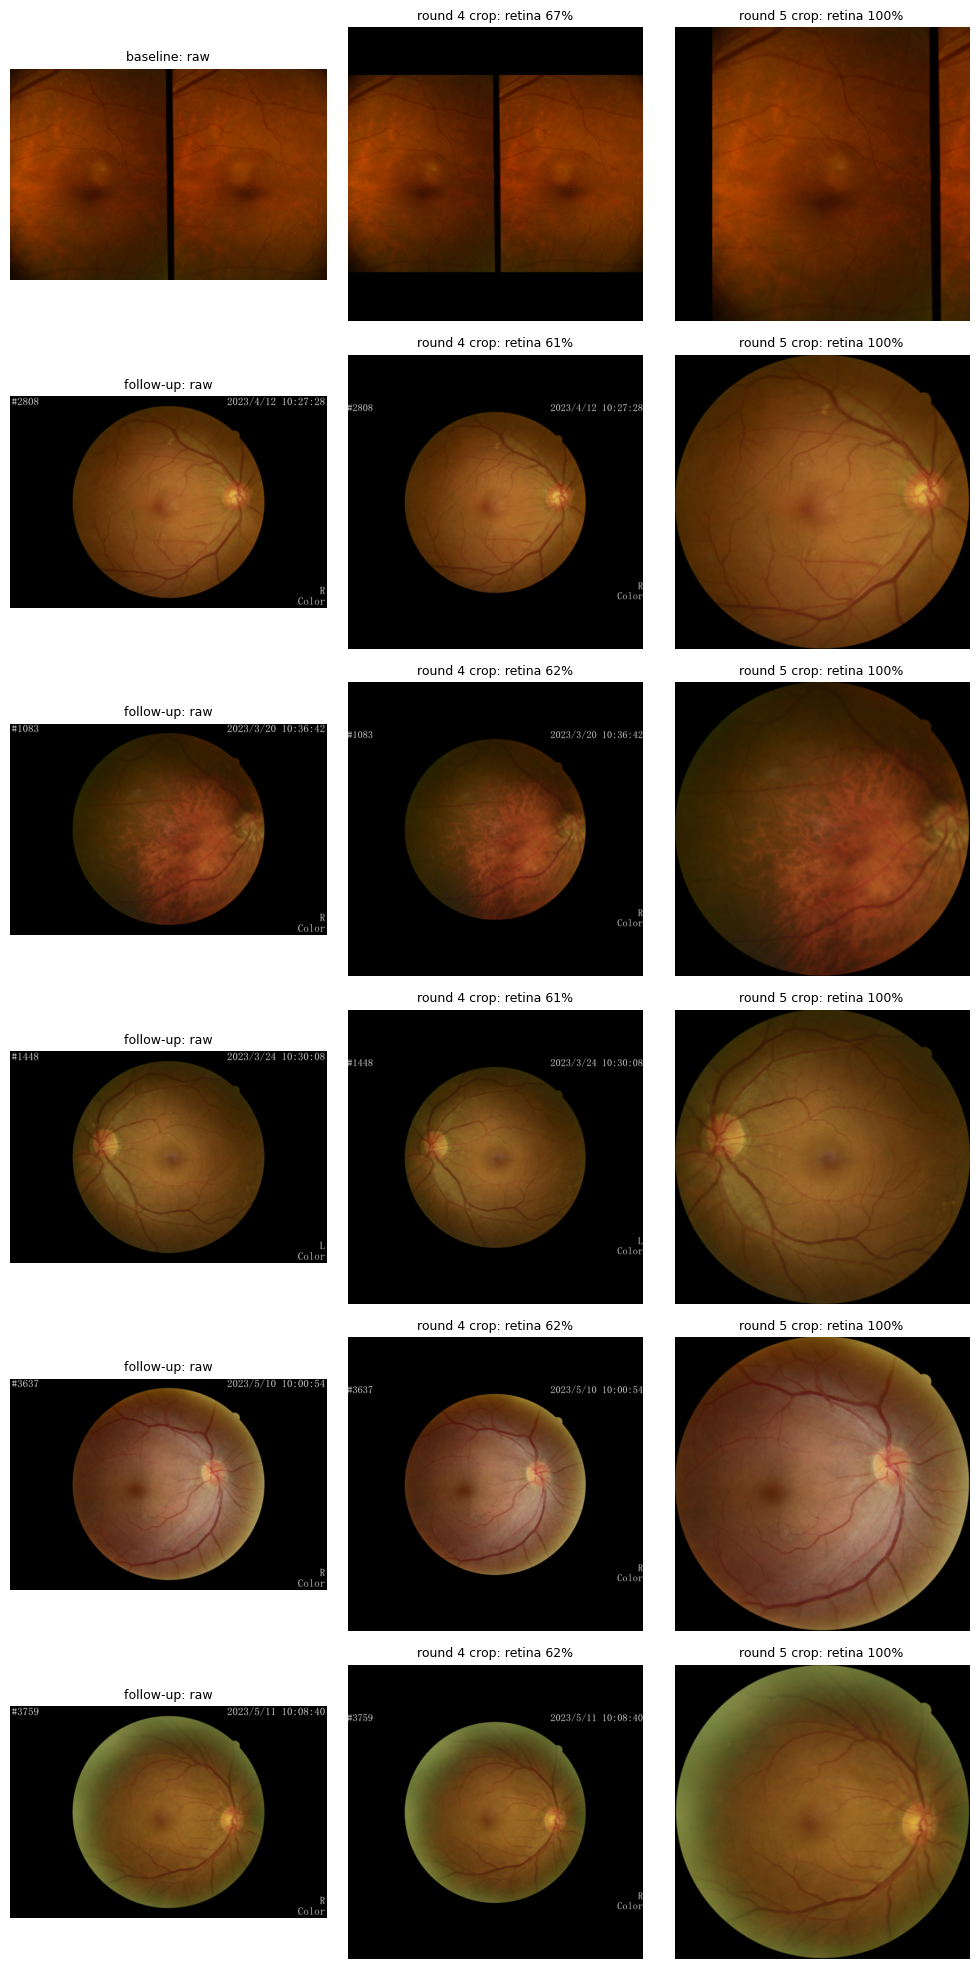

In [6]:
# Round 5: check the text-safe retina crop on the REAL Tianjin photos before the caches are built (2-3 h).
# Tianjin's follow-ups print the ID, date/time and "R / Color" in the black border; round 4's crop box stretched
# over that text, so the follow-up retina filled only ~60 % of the frame, off-centre. For a random sample of
# baseline and follow-up photos this measures how much of the cropped frame the retina fills (its widest extent
# / the box side; 100 % = edge to edge) with round 4's box and with round 5's, and draws the photos with the
# most text: raw | round 4 crop | round 5 crop. Expect round 5 at ~100 % for every photo, text or not.
# If it warns, don't run the cache cells -- look at the flagged photos first.
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
sys.path.insert(0, REPO_CODE_DIR)
import fundus_preprocess as fp

CROP_CHECK_N = 200   # photos measured (half baselines, half follow-ups); 0 = skip this check
CROP_CHECK_SHOW = 6  # photos drawn, most text first
MIN_FILL = 0.85      # warn when round 5's crop leaves the retina smaller than this share of the frame


def _crop_stats(path):
    os.environ['DRP_TEXT_SAFE_CROP'] = '1'
    img = Image.open(path).convert('RGB')
    w, h = img.size
    s = min(1.0, 512 / max(w, h))
    fov = np.array(img.resize((max(1, round(w * s)), max(1, round(h * s)))))[:, :, 1] > 10
    main = fp.main_fov_region(fov)  # the retina disc: largest bright region
    ys, xs = np.nonzero(main)
    diam = (max(ys.max() - ys.min(), xs.max() - xs.min()) + 1) / s if len(xs) else 0.0
    os.environ['DRP_TEXT_SAFE_CROP'] = '0'
    old = fp.retina_box(img)
    os.environ['DRP_TEXT_SAFE_CROP'] = '1'
    new = fp.retina_box(img)
    side = lambda b: (b[2] - b[0]) if b else max(w, h)  # noqa: E731
    return img, old, new, {
        'text_px': int(fov.sum() - main.sum()),                    # bright pixels outside the retina
        'retina_share': float(main.sum() / max(fov.sum(), 1)),     # < ~0.9: something big besides text
        'fill_r4': diam / side(old), 'fill_r5': diam / side(new), 'no_box': new is None}


if CROP_CHECK_N:
    _man = pd.read_csv(os.path.join(TIANJIN_DIR, 'corrected_manifest.csv'))
    _paths = (_man['baseline_path'].dropna().sample(min(CROP_CHECK_N // 2, len(_man)), random_state=0).tolist()
              + _man['followup_path'].dropna().sample(min(CROP_CHECK_N - CROP_CHECK_N // 2, len(_man)),
                                                     random_state=0).tolist())
    _rows, _imgs = [], {}
    for _rel in _paths:
        _p = os.path.join(TIANJIN_DIR, _rel)
        if not os.path.isfile(_p):
            continue
        _img, _old, _new, _st = _crop_stats(_p)
        _st['photo'] = _rel
        _st['kind'] = 'follow-up' if _rel in set(_man['followup_path']) else 'baseline'
        _rows.append(_st)
        _imgs[_rel] = (_img, _old, _new)
    os.environ['DRP_TEXT_SAFE_CROP'] = '1'
    CROP_CHECK = pd.DataFrame(_rows)
    assert len(CROP_CHECK), f'none of the sampled photos found under {TIANJIN_DIR}'
    CROP_CHECK['has_text'] = CROP_CHECK['text_px'] > 30
    print(f'{len(CROP_CHECK)} Tianjin photos measured; retina fill of the cropped frame (median):')
    print(CROP_CHECK.groupby(['kind', 'has_text'])[['fill_r4', 'fill_r5']].median()
          .map(lambda v: f'{v:.0%}').assign(n=CROP_CHECK.groupby(['kind', 'has_text']).size()))
    _bad = CROP_CHECK[CROP_CHECK['no_box'] | (CROP_CHECK['fill_r5'] < MIN_FILL) | (CROP_CHECK['retina_share'] < 0.9)]
    if len(_bad):
        print(f'\n⚠ {len(_bad)} photo(s) where round 5\'s crop may be wrong (no retina found, retina under '
              f'{MIN_FILL:.0%} of the frame, or a big bright region besides the retina) -- look at them before '
              'building the caches:')
        print(_bad[['photo', 'kind', 'fill_r4', 'fill_r5', 'retina_share', 'no_box']].to_string(index=False))
    else:
        print(f'\n✓ Round 5\'s crop fills >= {MIN_FILL:.0%} of the frame on every sampled photo '
              f'({int(CROP_CHECK["has_text"].sum())} with text in the border).')

    _show = pd.concat([_bad, CROP_CHECK.sort_values('text_px', ascending=False)]).drop_duplicates('photo')
    _show = _show.head(CROP_CHECK_SHOW)
    fig, axes = plt.subplots(len(_show), 3, figsize=(10, 3.3 * len(_show)), squeeze=False)
    for _ax_row, (_, _r) in zip(axes, _show.iterrows()):
        _img, _old, _new = _imgs[_r['photo']]
        for _ax, _im, _t in zip(_ax_row, (_img, _img.crop(_old) if _old else _img, _img.crop(_new) if _new else _img),
                                (f"{_r['kind']}: raw", f"round 4 crop: retina {_r['fill_r4']:.0%}",
                                 f"round 5 crop: retina {_r['fill_r5']:.0%}")):
            _ax.imshow(_im)
            _ax.set_title(_t, fontsize=9)
            _ax.axis('off')
        _ax_row[0].set_ylabel(os.path.basename(_r['photo']), fontsize=7)
    plt.tight_layout()
    plt.show()
else:
    print('Skipped (CROP_CHECK_N = 0)')

  Baseline sheet 'Baseline': patient_id <- 'ID', OS <- 'OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', OD <- 'OD Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', worse-eye <- 'At-risk Eye Grade（Worse eye）'
  Follow-up sheet '2 year follow-up': patient_id <- 'ID', OS <- 'OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', OD <- 'OD Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate 

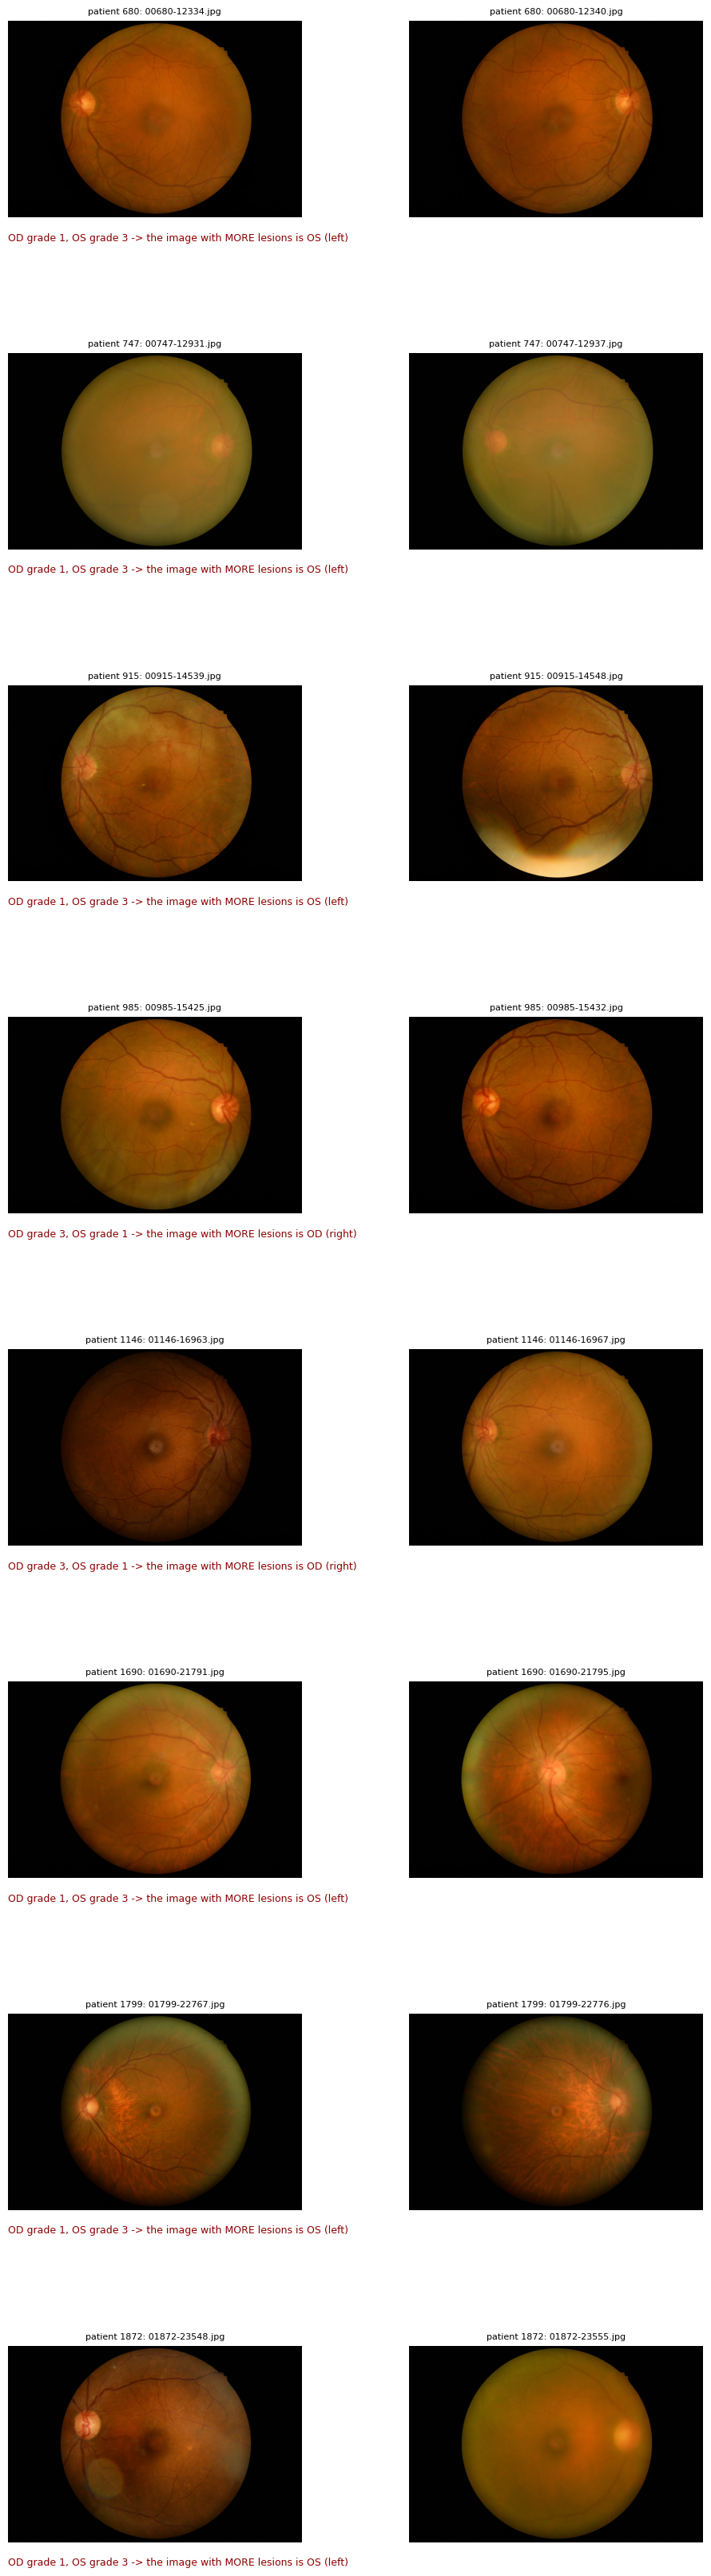

In [7]:
# Which eye does a left-of-centre optic disc mean in Tianjin's images? Shows patients whose two eyes have
# very different clinical grades: the image with clearly more lesions is the WORSE eye, whose name (OD/OS)
# the spreadsheet gives. Look at where its optic disc (the bright round spot) is. Then, in the next cell:
#   disc LEFT of centre in the right-eye (OD) images  -> LATERALITY_DISC_LEFT_IS = 'OD'
#   disc RIGHT of centre in the right-eye (OD) images -> LATERALITY_DISC_LEFT_IS = 'OS'
# (for left-eye (OS) images it is the other way round). Mixed / unclear -> leave it None.
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
sys.path.insert(0, f'{REPO_CODE_DIR}/module3'); sys.path.insert(0, REPO_CODE_DIR)
from dataset import TianjinSurvivalDataset
_g = TianjinSurvivalDataset._load_progression_labels(TIANJIN_DIR)
_m = pd.read_csv(f'{TIANJIN_DIR}/corrected_manifest.csv'); _m['patient_id'] = _m['patient_id'].astype(str).str.strip()
_g = _g[_g.baseline_od_grade_raw.between(1, 5) & _g.baseline_os_grade_raw.between(1, 5)]
_g = _g[(_g.baseline_od_grade_raw - _g.baseline_os_grade_raw).abs() >= 2]   # clearly different eyes
_pairs = [(r, _m[_m.patient_id == r.patient_id].baseline_path.tolist()) for r in _g.itertuples()]
_pairs = [(r, p) for r, p in _pairs if len(p) == 2][:8]
print(f'{len(_pairs)} patients with a >= 2-grade difference between eyes (grade 1 = no DR ... 5 = PDR)')
fig, axes = plt.subplots(len(_pairs), 2, figsize=(9, 4.2 * len(_pairs)), squeeze=False)
for row, (r, paths) in zip(axes, _pairs):
    worse = 'OD (right)' if r.baseline_od_grade_raw > r.baseline_os_grade_raw else 'OS (left)'
    for ax, p in zip(row, paths):
        ax.imshow(Image.open(f'{TIANJIN_DIR}/{p}').convert('RGB')); ax.axis('off')
        ax.set_title(f'patient {r.patient_id}: {p.split("/")[-1]}', fontsize=8)
    row[0].text(0, -0.12, f'OD grade {int(r.baseline_od_grade_raw)}, OS grade {int(r.baseline_os_grade_raw)} '
                f'-> the image with MORE lesions is {worse}', transform=row[0].transAxes, fontsize=9, color='darkred')
plt.tight_layout(); plt.show()

In [8]:
# Laterality resolution -- Tianjin-only, required before tianjin_dataset.py/apply_to_progression_data.py
# can run over it. Reuses a Drive-persisted copy if one exists (saves a few minutes).
# This branch re-tuned module1/resolve_eye_laterality.py (item 7.1), so it gets its own copy
# (module1_cache<RUN_SUFFIX>/); the settings come from notebook 11's EyePACS validation when it exists.
# _v2: the first file on this branch used the EyePACS validation's convention at only ~61 % accuracy
# (EyePACS mixes mirrored and non-mirrored images) -> 20.6 % of patients had both eyes labelled alike.
# Round 5: its own copy in this round's cache folder (the text-safe crop changes the field of view the
# optic-disc position is measured in); rounds 3/4 ('' / '_r4') share module1_cache<RUN_SUFFIX>/.
_LAT_DIR = 'module1_cache' + (RUN_SUFFIX if ROUND_TAG in ('', '_r4') else RUN_TAG)
LATERALITY_DRIVE_PATH = os.path.join(DRIVE_DATA_DIR, _LAT_DIR, 'laterality_resolved_v2.csv')
os.makedirs(os.path.dirname(LATERALITY_DRIVE_PATH), exist_ok=True)
LATERALITY_VALIDATION = os.path.join(DRIVE_DATA_DIR, 'module1_cache' + RUN_SUFFIX, 'laterality_eyepacs_validation.json')
LATERALITY_LOCAL_PATH = os.path.join(TIANJIN_DIR, 'laterality_resolved.csv')

if os.path.isfile(LATERALITY_DRIVE_PATH):
    shutil.copy(LATERALITY_DRIVE_PATH, LATERALITY_LOCAL_PATH)
    print(f'✓ Reused laterality_resolved.csv from Drive')
else:
    %cd {REPO_CODE_DIR}
    # LATERALITY_DISC_LEFT_IS: which eye a left-of-centre optic disc means in Tianjin's images. None =
    # the script's default ('OD', what every earlier run used), unless notebook 11's EyePACS validation
    # is clearly reliable (>= 80 % accuracy). Check a few Tianjin images of known right eyes by eye and
    # set 'OD' or 'OS' here -- that is the real answer (after changing it, delete laterality_resolved_v2.csv
    # on Drive so it is recomputed).
    LATERALITY_DISC_LEFT_IS = 'OS'  # round 3 set this by hand after checking Tianjin images by eye
    _lat_args = ''
    _b = None
    if os.path.isfile(LATERALITY_VALIDATION):
        import json as _json
        _b = _json.load(open(LATERALITY_VALIDATION))['best']
    if LATERALITY_DISC_LEFT_IS:
        _lat_args = f' --disc-left-is {LATERALITY_DISC_LEFT_IS}'
        print(f'Laterality: --disc-left-is {LATERALITY_DISC_LEFT_IS} (set by hand)')
    elif _b and _b['accuracy_on_decided'] >= 0.8:
        _lat_args = (f" --disc-left-is {_b['disc_left_is']} --margin {_b['margin']}"
                     + (' --legacy-estimator' if _b['estimator'] == 'legacy' else ''))
        print(f"Laterality settings from the EyePACS validation: {_lat_args} "
              f"(accuracy {_b['accuracy_on_decided']:.1%}, {_b['uncertain_rate']:.1%} uncertain)")
    else:
        print('\u26a0 Laterality: script defaults (--disc-left-is OD --margin 0.1) -- '
              + (f"the EyePACS validation is too weak to use ({_b['accuracy_on_decided']:.1%} accuracy). "
                 if _b else 'no EyePACS validation. ')
              + 'Set LATERALITY_DISC_LEFT_IS after checking a few Tianjin images by eye.')
    !python module1/resolve_eye_laterality.py --dataset-dir "{TIANJIN_DIR}"{_lat_args}
    os.makedirs(os.path.dirname(LATERALITY_DRIVE_PATH), exist_ok=True)
    shutil.copy(LATERALITY_LOCAL_PATH, LATERALITY_DRIVE_PATH)
    print(f'✓ Computed and persisted laterality_resolved.csv to Drive')


✓ Reused laterality_resolved.csv from Drive


In [9]:
# Locate Module 1 checkpoints (classifier + EX/MA + HE/SE if trained) -- shared by all 3
# apply_to_progression_data.py calls below.
import glob

SEG_DIR   = os.path.join(MODULE1_RUNS, 'segmentation')
# Module 1 grader: 'eyepacs' (default) = DRG-Net's classifier trained on EyePACS (notebook 11, training
# capped at 3000 images/grade); 'fgadr' = the FGADR grader. Notebook 04_05's grader-comparison cell scores
# both on Tianjin's clinical grades -- set the one it recommends in notebooks 04_05, 06, 08, 09 and 10.
# With 'eyepacs' and no EyePACS grader on Drive, the FGADR one is used.
CLASSIFIER_RUN = 'eyepacs'
if not glob.glob(os.path.join(MODULE1_RUNS, 'classification', CLASSIFIER_RUN, 'saves', '*.pt')):
    print(f'\u26a0 No {CLASSIFIER_RUN} grader in {MODULE1_RUNS} yet -- using the FGADR one')
    CLASSIFIER_RUN = 'fgadr'
CLS_SAVES = os.path.join(MODULE1_RUNS, 'classification', CLASSIFIER_RUN, 'saves')
# Classifier input normalisation must match its training config (eyepacs_poc.yaml differs).
CLS_NORM_ARGS = ' --classifier-norm eyepacs' if CLASSIFIER_RUN == 'eyepacs' else ''

# EyePACS: best_validation_weights.pt (picked on the Kaggle public test, kept apart from its test set);
# FGADR: final_weights.pt (its "validation" set IS its test set, so the best-validation pick is optimistic).
_pref  = (['best_validation_weights.pt', 'final_weights.pt'] if CLASSIFIER_RUN == 'eyepacs'
          else ['final_weights.pt', 'best_validation_weights.pt'])
_cands = [os.path.join(CLS_SAVES, n) for n in _pref] + sorted(
    glob.glob(os.path.join(CLS_SAVES, '*.pt')), key=os.path.getmtime, reverse=True)
CLS_CKPT = next((p for p in _cands if os.path.isfile(p)), None)
assert CLS_CKPT, f"No classifier .pt in {CLS_SAVES} -- run notebook 02/03 (MODULE1_SOURCE='poc') or 11 ('drgnet' / 'drgnet_combined') first"

EX_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'ex', 'model_2.pth.tar')
MA_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'ma', 'model_2.pth.tar')
for _p in (CLS_CKPT, EX_CKPT, MA_CKPT):
    assert os.path.isfile(_p), f"missing checkpoint: {_p} -- run notebook 02/03 (MODULE1_SOURCE='poc') or 11 ('drgnet' / 'drgnet_combined') first"

HE_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'he', 'model_2.pth.tar')
SE_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'se', 'model_2.pth.tar')
print('classifier :', CLS_CKPT)
print('EX seg     :', EX_CKPT)
print('MA seg     :', MA_CKPT)
print('HE seg     :', HE_CKPT if os.path.isfile(HE_CKPT) else 'not trained yet')
print('SE seg     :', SE_CKPT if os.path.isfile(SE_CKPT) else 'not trained yet')

_extra_seg_args = ''
if os.path.isfile(HE_CKPT):
    _extra_seg_args += f' --seg-checkpoint HE="{HE_CKPT}"'
if os.path.isfile(SE_CKPT):
    _extra_seg_args += f' --seg-checkpoint SE="{SE_CKPT}"'

os.makedirs(MODULE1_CACHE_DIR, exist_ok=True)


classifier : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/classification/eyepacs/saves/best_validation_weights.pt
EX seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_ex/model_2.pth.tar
MA seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_ma/model_2.pth.tar
HE seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_he/model_2.pth.tar
SE seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_ft_models_se/model_2.pth.tar


In [10]:
# Which grader for CLASSIFIER_RUN? Scores both graders (each with both of its saved weights) against
# Tianjin's CLINICAL grades, baseline + 2-year follow-up -- the images the pipeline grades. Their own
# test-set numbers in notebook 11 can't be compared (different datasets; FGADR's test set also picks its
# epoch). Primary view = per patient: worse-eye clinical grade vs. the highest grade given to that
# patient's images (needs no left/right); the per-eye view depends on the laterality file. ~10 min on a
# T4. Saved to Drive; delete the JSON to re-run. Then set the recommended grader in notebooks 04_05
# (cell above -- before the cache cells below), 06, 08, 09 and 10.
RUN_GRADER_COMPARISON = True
GRADER_COMPARISON_JSON = os.path.join(MODULE1_CACHE_DIR, 'grader_comparison_tianjin.json')
_cls_root = os.path.join(MODULE1_RUNS, 'classification')
_graders = {'fgadr': 'fgadr/saves/final_weights.pt', 'fgadr_bestval': 'fgadr/saves/best_validation_weights.pt',
            'eyepacs': 'eyepacs/saves/best_validation_weights.pt', 'eyepacs_final': 'eyepacs/saves/final_weights.pt'}
_grader_args = ''.join(f' --grader {n}="{os.path.join(_cls_root, f)}"' for n, f in _graders.items()
                       if os.path.isfile(os.path.join(_cls_root, f)))
if RUN_GRADER_COMPARISON and not os.path.isfile(GRADER_COMPARISON_JSON):
    %cd {REPO_CODE_DIR}
    !python module1/compare_graders_tianjin.py --tianjin-dir "{TIANJIN_DIR}"{_grader_args} --out "{GRADER_COMPARISON_JSON}"
if os.path.isfile(GRADER_COMPARISON_JSON):
    import json as _json
    _gc = _json.load(open(GRADER_COMPARISON_JSON))
    for _n, _r in _gc['graders'].items():
        _m = _r['patient']['both']
        print(f"{_n:<15} patient-level, both visits: kappa {(_m.get('quadratic_kappa') or 0):.3f}  "
              f"accuracy {_m['accuracy']:.3f}  within-one {_m['within_one_grade']:.3f}  (n={_m['n']})")
    _rec = (_gc['summary']['recommended'] or '').split('_')[0]
    print(f"\nRecommended: CLASSIFIER_RUN = '{_rec}'  (currently '{CLASSIFIER_RUN}')")
    if _rec and _rec != CLASSIFIER_RUN:
        print('\u26a0 Set it in the checkpoint cell above and re-run that cell before building the caches below '
              '(and in notebooks 06, 08, 09, 10).')

fgadr           patient-level, both visits: kappa 0.003  accuracy 0.019  within-one 0.058  (n=1133)
fgadr_bestval   patient-level, both visits: kappa -0.002  accuracy 0.024  within-one 0.109  (n=1133)
eyepacs         patient-level, both visits: kappa 0.508  accuracy 0.708  within-one 0.837  (n=1133)
eyepacs_final   patient-level, both visits: kappa 0.421  accuracy 0.654  within-one 0.787  (n=1133)

Recommended: CLASSIFIER_RUN = 'eyepacs'  (currently 'eyepacs')


In [11]:
# This branch's module1/apply_to_progression_data.py already has --checkpoint-every/--resume
# (so a long run survives a lost Colab session), plus the per-lesion biomarker stats and options
# notebooks 09-11 need. The manual upload of a local copy is therefore OFF by default: an older
# local copy would replace this branch's version for this session and drop those features.
# Only set this to True if your local copy has fixes that were never pushed.
UPLOAD_LOCAL_COPY = False

if UPLOAD_LOCAL_COPY:
    from google.colab import files
    uploaded = files.upload()  # pick module1/apply_to_progression_data.py
    for fname in uploaded:
        if fname != 'apply_to_progression_data.py':
            print(f'Skipping unexpected file: {fname}')
            continue
        dest = os.path.join(REPO_CODE_DIR, 'module1', fname)
        shutil.move(fname, dest)
        print(f'Overwrote {dest}')

!python {REPO_CODE_DIR}/module1/apply_to_progression_data.py --help | grep -E "checkpoint-every|resume"


                                    [--image-list IMAGE_LIST] [--resume]
  --resume              If --out already exists, load it and skip images
  --save-every, --checkpoint-every SAVE_EVERY
                        = only at the end). --checkpoint-every is the same


Classifier normalisation: eyepacs mean=[0.425753653049469, 0.29737451672554016, 0.21293757855892181] std=[0.27670302987098694, 0.20240527391433716, 0.1686241775751114]


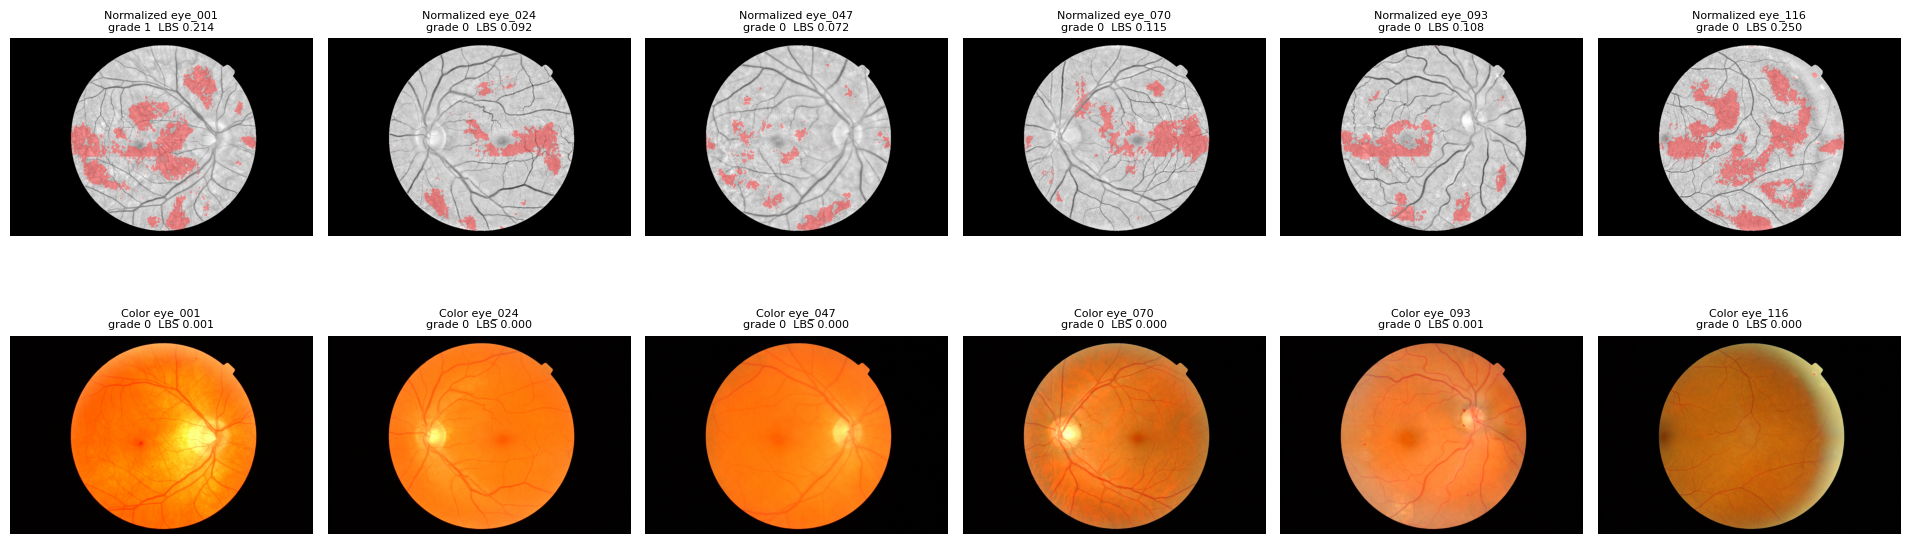

FundusImagesNormalized   median LBS 0.1112  (Tianjin / FIRE grade-0 eyes: ~0.0002-0.005)
FundusImagesColor        median LBS 0.0002  (Tianjin / FIRE grade-0 eyes: ~0.0002-0.005)


In [12]:
# Round 4, Phase-0 check (item R4-0.1): Module 1's lesion maps on the SAME LongDR eyes from the contrast-
# normalised images (round 3) and the raw colour photos (round 4). On normalised images the segmenters
# marked 10-30 % of mostly normal retinas as lesion. Look at the red overlays: the colour row should show
# few, small, plausible lesions; if the colour photos look worse, set DRP_LONGDR_FOLDER back in the first
# cell and report LongDR's lesion maps as unreliable (or drop LongDR's masks from conditioning).
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, f'{REPO_CODE_DIR}/module1')
import torch, apply_to_progression_data as m1
if CLS_NORM_ARGS:
    m1.set_classifier_norm('eyepacs')
_dev = 'cuda' if torch.cuda.is_available() else 'cpu'
_clf = m1.load_classifier(CLS_CKPT, device=_dev)
_segs = {'EX': EX_CKPT, 'MA': MA_CKPT, 'HE': HE_CKPT, 'SE': SE_CKPT}
_segs = {k: m1.load_segmentation_model(v, device=_dev) for k, v in _segs.items() if os.path.isfile(v)}
_root = '/content/data/LongDRScreening_20150209'
_eyes = sorted(d for d in os.listdir(f'{_root}/FundusImagesColor') if d.startswith('eye_'))[:: 23][:6]
_folders = [d for d in ('FundusImagesNormalized', 'FundusImagesColor') if os.path.isdir(f'{_root}/{d}')]
fig, axes = plt.subplots(len(_folders), len(_eyes), figsize=(3.2 * len(_eyes), 3.4 * len(_folders)), squeeze=False)
LONGDR_CHECK = {}
for r, folder in enumerate(_folders):
    for c, eye in enumerate(_eyes):
        _cand = sorted(f for f in os.listdir(f'{_root}/{folder}/{eye}') if f.lower().endswith('.png'))
        if not _cand:
            continue
        _p = f'{_root}/{folder}/{eye}/{_cand[0]}'
        _out = m1.process_image(_p, _clf, _segs, device=_dev)
        LONGDR_CHECK.setdefault(folder, []).append(_out['lbs'])
        _rgb = np.array(m1._load_rgb(_p)).astype(float) / 255
        _ov = _rgb.copy(); _ov[_out['mask'] > 0] = [1, 0, 0]
        axes[r][c].imshow(0.6 * _rgb + 0.4 * _ov); axes[r][c].axis('off')
        axes[r][c].set_title(f"{folder.replace('FundusImages', '')} {eye}\ngrade {_out['grade']}  LBS {_out['lbs']:.3f}", fontsize=8)
plt.tight_layout(); plt.show()
for folder, v in LONGDR_CHECK.items():
    print(f'{folder:<24} median LBS {np.median(v):.4f}  (Tianjin / FIRE grade-0 eyes: ~0.0002-0.005)')
del _clf, _segs
if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [13]:
# FIRE
%cd {REPO_CODE_DIR}/module1
!python apply_to_progression_data.py \
    --images-dir /content/data/FIRE_dataset/FIRE/Images \
    --classifier-checkpoint "{CLS_CKPT}"{CLS_NORM_ARGS} \
    --seg-checkpoint EX="{EX_CKPT}" --seg-checkpoint MA="{MA_CKPT}"{_extra_seg_args} \
    --checkpoint-every 50 --resume \
    --out "{MODULE1_CACHE_DIR}/module1_outputs_fire.pt"


/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc/module1
Classifier normalisation: eyepacs mean=[0.425753653049469, 0.29737451672554016, 0.21293757855892181] std=[0.27670302987098694, 0.20240527391433716, 0.1686241775751114]
Lesion segmentation: tiled (retina 1280 px, 512 px tiles, stride 384) | retina crop: on
--resume: 268 images already cached in /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r5/module1_outputs_fire.pt, skipping them
✓ wrote 268 entries to /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r5/module1_outputs_fire.pt


In [14]:
# LongDR -- round 4: the raw colour photos (DRP_LONGDR_FOLDER, first cell; see the check above). The cache keys
# (eye_XXX__visit_N_image_M) are the same for both folders, so the loaders match it either way.
!python apply_to_progression_data.py \
    --images-dir "{LONGDR_IMAGES}" \
    --classifier-checkpoint "{CLS_CKPT}"{CLS_NORM_ARGS} \
    --seg-checkpoint EX="{EX_CKPT}" --seg-checkpoint MA="{MA_CKPT}"{_extra_seg_args} \
    --checkpoint-every 50 --resume \
    --out "{MODULE1_CACHE_DIR}/module1_outputs_longdr.pt"


Classifier normalisation: eyepacs mean=[0.425753653049469, 0.29737451672554016, 0.21293757855892181] std=[0.27670302987098694, 0.20240527391433716, 0.1686241775751114]
Lesion segmentation: tiled (retina 1280 px, 512 px tiles, stride 384) | retina crop: on
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc/module1/apply_to_progression_data.py:194: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return np.array(Image.fromarray(soft.astype(np.float32), mode="F").resize(size, Image.BILINEAR))
✓ [1/1120] eye_001__visit_1_image_1: grade=0 lbs=0.00067 (lesions: ['EX', 'HE', 'MA', 'SE'])
✓ [2/1120] eye_001__visit_1_image_2: grade=0 lbs=0.00045 (lesions: ['EX', 'HE', 'MA', 'SE'])
✓ [3/1120] eye_001__visit_1_image_3: grade=0 lbs=0.00009 (lesions: ['EX', 'HE', 'MA', 'SE'])
✓ [4/1120] eye_001__visit_1_image_4: grade=0 lbs=0.00089 (lesions: ['EX', 'HE', 'MA', 'SE'])
✓ [5/1120] eye_001__visit_2_image_1: grade=0 lbs=0.00002 (lesions: ['EX

In [15]:
# Tianjin -- the slow one. If this gets interrupted, just re-run this exact cell: --resume
# means it picks up where it left off instead of starting over.
!python apply_to_progression_data.py \
    --images-dir "{TIANJIN_DIR}/baseline fundus images" \
    --classifier-checkpoint "{CLS_CKPT}"{CLS_NORM_ARGS} \
    --seg-checkpoint EX="{EX_CKPT}" --seg-checkpoint MA="{MA_CKPT}"{_extra_seg_args} \
    --checkpoint-every 50 --resume \
    --out "{MODULE1_CACHE_DIR}/module1_outputs_tianjin.pt"


Classifier normalisation: eyepacs mean=[0.425753653049469, 0.29737451672554016, 0.21293757855892181] std=[0.27670302987098694, 0.20240527391433716, 0.1686241775751114]
Lesion segmentation: tiled (retina 1280 px, 512 px tiles, stride 384) | retina crop: on
Skipped 16 macOS '._*' metadata files (not images)
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc/module1/apply_to_progression_data.py:194: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return np.array(Image.fromarray(soft.astype(np.float32), mode="F").resize(size, Image.BILINEAR))
✓ [1/1234] 00194__00194-7256: grade=0 lbs=0.00135 (lesions: ['EX', 'HE', 'MA', 'SE'])
✓ [2/1234] 00194__00194-7261: grade=0 lbs=0.00348 (lesions: ['EX', 'HE', 'MA', 'SE'])
✓ [3/1234] 00197__00197-7300: grade=0 lbs=0.00112 (lesions: ['EX', 'HE', 'MA', 'SE'])
✓ [4/1234] 00197__00197-7305: grade=0 lbs=0.00050 (lesions: ['EX', 'HE', 'MA', 'SE'])
✓ [5/1234] 00198__00198-7325: grade=0 lbs=0.0015

In [16]:
# Round 4, Phase-0 checks on the finished caches (items R4-0.2 / R4-0.3):
# (a) LBS by predicted grade per source -- grade-0 eyes should have LBS near 0 in EVERY source (round 3:
#     LongDR 0.13 vs Tianjin 0.001 / FIRE 0.0002, from the normalised LongDR images).
import torch, numpy as np, pandas as pd
_rows = []
for _src in ('fire', 'longdr', 'tianjin'):
    _c = torch.load(f'{MODULE1_CACHE_DIR}/module1_outputs_{_src}.pt', weights_only=False)
    _rows += [{'source': _src, 'grade': int(v['grade']), 'lbs': float(v['lbs'])} for v in _c.values()]
_df = pd.DataFrame(_rows)
print('Median LBS by Module 1 grade (n in brackets):')
display(_df.groupby(['source', 'grade'])['lbs'].agg(['median', 'count']).unstack('grade').round(4))

# (b) Grader resolution check: the grader on REAL Tianjin images at full resolution and after shrinking to
#     128 / 256 px (Module 2's sizes) -- the best agreement a perfect Generator could get on the cascade
#     metric at each size, and whether 256 px is worth its cost (MODULE2_IMAGE_SIZE in notebooks 06-10).
#     ~15 min on an L4 for 300 eye-pairs x 2 graders. Saved to Drive; delete the JSON to re-run.
GRADER_RES_JSON = os.path.join(MODULE1_CACHE_DIR, 'grader_resolution_check.json')
_g = {'eyepacs': ('eyepacs/saves/best_validation_weights.pt', 'eyepacs'), 'fgadr': ('fgadr/saves/final_weights.pt', 'fgadr')}
_gargs = ''.join(f' --grader {n}="{os.path.join(MODULE1_RUNS, "classification", p)}:{norm}"'
                 for n, (p, norm) in _g.items() if os.path.isfile(os.path.join(MODULE1_RUNS, 'classification', p)))
if not os.path.isfile(GRADER_RES_JSON):
    %cd {REPO_CODE_DIR}
    !python tools/grader_resolution_check.py --tianjin-dir "{TIANJIN_DIR}" --tianjin-module1-cache "{MODULE1_CACHE_DIR}/module1_outputs_tianjin.pt"{_gargs} --sizes 128 256 --max-pairs 300 --out "{GRADER_RES_JSON}"
else:
    import json as _json
    _r = _json.load(open(GRADER_RES_JSON))
    for _n, _gr in _r['graders'].items():
        print(_n, {k: round(v['vs_clinical']['quadratic_kappa'] or 0, 3) for k, v in _gr['results'].items()}, '(kappa vs clinical)')
    print('Recommendation:', _r.get('recommendation'))

Median LBS by Module 1 grade (n in brackets):


median                                  count                        
grade         0       1       2       3       4      0     1      2    3     4
source                                                                        
fire     0.0002  0.0026  0.0220  0.0579     NaN  223.0  19.0   21.0  5.0   NaN
longdr   0.0003  0.0006  0.0004     NaN  0.0041  968.0  21.0  130.0  NaN   1.0
tianjin  0.0011  0.0009  0.0037     NaN  0.0108  981.0  48.0  171.0  NaN  34.0

/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
✓ Loaded Module 1 cache: 1234 images (/content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals_r5/module1_outputs_tianjin.pt)
  Total eye-pairs in corrected_manifest.csv: 1115
  Baseline sheet 'Baseline': patient_id <- 'ID', OS <- 'OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', OD <- 'OD Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', worse-eye <- 'At-risk Eye Grade（Worse eye）'
  Follow-up sheet '2 year follow-up': patient_id <- 'ID', OS <- 'OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Mo

## Done

All 3 caches are now on Drive under `module1_cache<RUN_TAG>/` -- round 4 with the default
`MODULE1_SOURCE='drgnet_combined'`: `module1_cache_drgnet_comb_prefinals_r4/` (round 3:
`module1_cache_drgnet_comb_prefinals/`; `'drgnet'` / `'poc'` get `_drgnet` / no source suffix). Next:
notebook 09 (EyePACS pretraining), then 06 with the same `MODULE1_SOURCE` and `ROUND_TAG`, then 07, 08, 10.

## Before closing the runtime

Files written to Drive upload in the background. Run this last cell and wait for the ✓ before
disconnecting or deleting the runtime -- otherwise large files written at the end (model weights,
caches) can be lost.

In [17]:
from google.colab import drive
drive.flush_and_unmount()
print('✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.')

✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.
